# MANGAL DRISHTI — Step 01: Dataset Exploration & Validation

**Project:** Mars Autonomous Navigation, Geospatial Analysis & Learning — Deep Rover Intelligence, Segmentation, Terrain Recognition & Imaging  
**Dataset:** NASA/JPL AI4MARS (`v0.6`, DOI: `10.5281/zenodo.15995036`)  

This notebook inspects the acquired NASA/JPL AI4MARS dataset, verifies image-mask pairing and pixel-level ground-truth encoding, quantifies terrain class imbalance across splits and missions, and inspects representative rover imagery alongside qualitative external NASA raw imagery.

In [1]:
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

PROJECT_ROOT = Path("..").resolve()
RAW_ROOT = PROJECT_ROOT / "datasets" / "raw" / "ai4mars"
INSP_ROOT = PROJECT_ROOT / "datasets" / "inspection"
EXT_ROOT = PROJECT_ROOT / "datasets" / "samples" / "external_nasa"

summary = json.loads((INSP_ROOT / "dataset_summary.json").read_text(encoding="utf-8"))
validation = json.loads((INSP_ROOT / "validation_report.json").read_text(encoding="utf-8"))
label_keys = json.loads((RAW_ROOT / "label_keys.json").read_text(encoding="utf-8"))

print("Validation Status:", validation["status"])
print("Total Verified Image-Mask Pairs:", validation["validated_image_mask_pairs"])
print("Total Size on Disk (MB):", summary["inventory"]["total_size_mb"])
print("Official NAV Label Keys:", label_keys["NAV"])

Validation Status: PASS
Total Verified Image-Mask Pairs: 2326
Total Size on Disk (MB): 743.39
Official NAV Label Keys: {'0': 'soil', '1': 'bedrock', '2': 'sand', '3': 'big rock', '255': None}


### Analysis: Acquisition & Validation Integrity
The inspection engine confirms the official `NAV` pixel mapping from `label_keys.json` (`0: soil`, `1: bedrock`, `2: sand`, `3: big rock`, `255: NULL/unlabeled`) and loads the verified dataset statistics from `dataset_summary.json` and `validation_report.json`. Let us now tabulate split counts, correspondence checks, and file-level integrity.

In [2]:
split_df = pd.DataFrame([
    {
        "Split": k,
        "Pairs": v["num_images"],
        "Total Pixels (M)": round(v["total_pixels"] / 1e6, 2),
        "Labeled Pixels (M)": round(v["labeled_pixels"] / 1e6, 2),
        "Labeled Coverage (%)": v["labeled_pct"],
        "Unlabeled/NULL (%)": v["unlabeled_pct"],
        "Imbalance Ratio (Max:Min)": v["max_to_min_class_imbalance_ratio"],
    }
    for k, v in summary["split_terrain_distributions"].items()
])
display(split_df)

checks = pd.DataFrame([
    ("Corrupted Images", validation["image_validation"]["corrupted_image_count"]),
    ("Corrupted Masks", validation["mask_validation"]["corrupted_mask_count"]),
    ("Dimension Mismatches", validation["mask_validation"]["dimension_mismatch_count"]),
    ("Invalid Mask Values", validation["mask_validation"]["invalid_pixel_value_mask_count"]),
    ("Train/Test ID Leakage", validation["correspondence_checks"]["train_test_id_leakage_count"]),
    ("Missing Manifest Pairs", validation["correspondence_checks"]["missing_manifest_pairs"]),
    ("Exact Duplicate Images", validation["duplicate_checks"]["exact_duplicate_image_groups"]),
], columns=["Integrity Check", "Count"])
display(checks)

,Split,Pairs,Total Pixels (M),Labeled Pixels (M),Labeled Coverage (%),Unlabeled/NULL (%),Imbalance Ratio (Max:Min)
0,train,1500,1572.86,806.47,51.2739,48.7261,60.70
1,val,300,314.57,179.83,57.1667,42.8333,958.29
2,test_msl,322,337.64,116.98,34.6461,65.3539,773.11
3,test_mer,204,213.91,55.71,26.0422,73.9578,39.78


,Integrity Check,Count
0,Corrupted Images,0
1,Corrupted Masks,0
2,Dimension Mismatches,0
3,Invalid Mask Values,0
4,Train/Test ID Leakage,0
5,Missing Manifest Pairs,0
6,Exact Duplicate Images,0


### Analysis: Data Quality & Split Hygiene
Every acquired split—chronological SCLK-partitioned `train` and `val` sets (MSL Curiosity) as well as the held-out expert gold-standard `test_msl` and `test_mer` (Opportunity & Spirit) sets—is verified for corruption, dimension alignment, valid label IDs, and zero train/test overlap. Notably, the expert `min3-100agree` test masks have substantially lower labeled pixel coverage than the crowdsourced training masks because three independent experts had to agree 100% at each pixel.

Sample ID: NLB_421445249EDR_F0060000NCAM12754M1 | Mission: MSL (Curiosity) | Camera: NavCam Left-B
Image shape/dtype: (1024, 1024), uint8, intensity=[6, 255]
Mask  shape/dtype: (1024, 1024), uint8
  Pixel value   0 (      soil):   10746 px (  1.02%)
  Pixel value   1 (   bedrock):  384582 px ( 36.68%)
  Pixel value   2 (      sand):   24949 px (  2.38%)
  Pixel value   3 (  big rock):  107933 px ( 10.29%)
  Pixel value 255 (      None):  520366 px ( 49.63%)


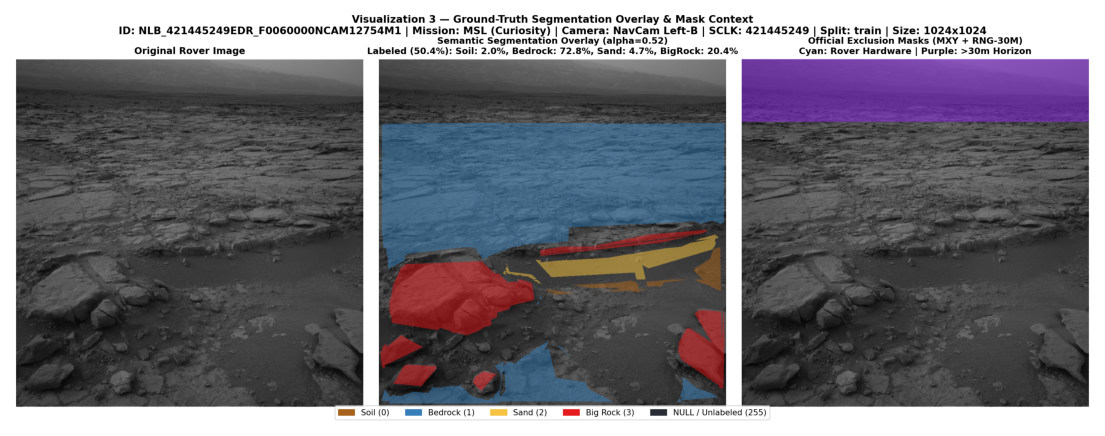

In [3]:
hero = summary["representative_samples"]["multi_class_hero_msl"]
img_path = RAW_ROOT / hero["image_relpath"]
mask_path = RAW_ROOT / hero["mask_relpath"]

img_arr = np.asarray(Image.open(img_path))
mask_arr = np.asarray(Image.open(mask_path))
uvals, ucounts = np.unique(mask_arr, return_counts=True)

print(f"Sample ID: {hero['id']} | Mission: {hero['mission']} | Camera: {hero['camera']}")
print(f"Image shape/dtype: {img_arr.shape}, {img_arr.dtype}, intensity=[{img_arr.min()}, {img_arr.max()}]")
print(f"Mask  shape/dtype: {mask_arr.shape}, {mask_arr.dtype}")
for uv, uc in zip(uvals, ucounts):
    cname = label_keys["NAV"].get(str(int(uv)), "unknown")
    print(f"  Pixel value {int(uv):3d} ({str(cname):>10s}): {int(uc):7d} px ({uc / mask_arr.size * 100:6.2f}%)")

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.imshow(Image.open(INSP_ROOT / "03_segmentation_overlay.png"))
ax.axis("off")
plt.show()

### Analysis: Pixel Encoding & Exclusion Masks
The ground-truth mask is stored as a single-channel 8-bit grayscale PNG where terrain classes occupy values `0` through `3` and ignored regions (distant terrain `>30m`, rover deck/hardware masked by `MXY`, sky, and low-consensus pixels) are encoded as `255`. Because `0–3` are adjacent near-zero intensities, opening raw masks in standard image viewers renders terrain nearly pitch black—confirming why palette mapping is mandatory for visual inspection.

,Pixel ID,Terrain Class,Pixel Count,Share of All Pixels (%),Share of Labeled Pixels (%),Images Containing Class,Image Presence (%)
0,0,soil,548583531,22.4923,47.3330,1320,56.75
1,1,bedrock,500362927,20.5152,43.1725,1245,53.53
2,2,sand,102275761,4.1934,8.8246,448,19.26
3,3,big rock,7764313,0.3183,0.6699,254,10.92
4,255,unlabeled_null,1280001244,52.4808,NaN,2326,100.00


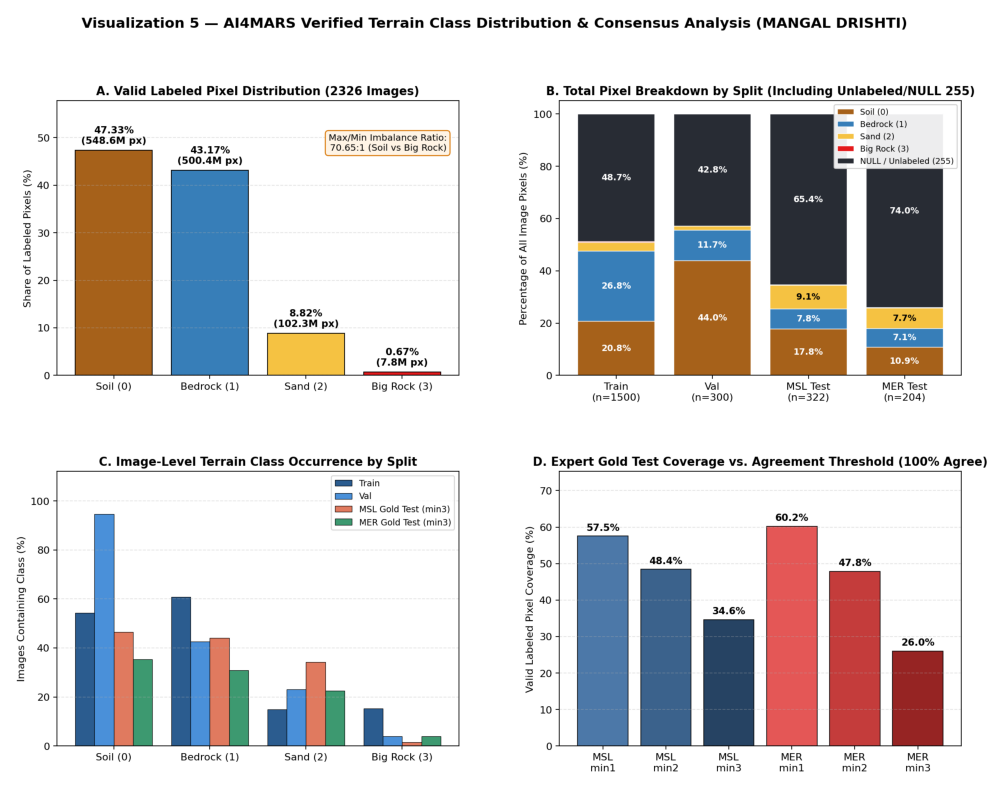

In [4]:
overall = summary["overall_terrain_distribution"]
class_rows = []
for cid in ["0", "1", "2", "3", "255"]:
    c = overall["classes"][cid]
    class_rows.append({
        "Pixel ID": int(cid),
        "Terrain Class": c["class_name"],
        "Pixel Count": c["pixel_count"],
        "Share of All Pixels (%)": c["pct_of_all_pixels"],
        "Share of Labeled Pixels (%)": c["pct_of_labeled_pixels"],
        "Images Containing Class": c["images_with_class"],
        "Image Presence (%)": c["pct_images_with_class"],
    })
class_df = pd.DataFrame(class_rows)
display(class_df)

fig, ax = plt.subplots(figsize=(14, 10))
ax.imshow(Image.open(INSP_ROOT / "terrain_distribution.png"))
ax.axis("off")
plt.show()

### Analysis: Class Imbalance & Expert Threshold Dynamics
Across the acquired dataset, `soil` and `bedrock` dominate labeled pixels while `big rock` represents only a tiny fraction of labeled area despite appearing in a substantial fraction of frames. In Step 2, training losses must mask out `255` (`ignore_index=255`) and compensate for the severe class imbalance using inverse/effective-number class weights or hybrid Focal + Dice loss so hazard-critical `big rock` and `sand` regions are not overshadowed.

,mission,sol,instrument,filename
0,Mars 2020 (Perseverance),2024,MCZ_LEFT,m2020_sol2024_ZL0_2024_0846622583_145EBY_N0930000ZCAM10058_1100LMJ.jpg
1,Mars 2020 (Perseverance),2024,MCZ_LEFT,m2020_sol2024_ZL0_2024_0846622583_145ECM_N0930000ZCAM10058_1100LMJ.jpg
2,Mars 2020 (Perseverance),2024,MCZ_RIGHT,m2020_sol2024_ZR0_2024_0846622583_145EBY_N0930000ZCAM10058_1100LMJ.jpg
3,Mars 2020 (Perseverance),2024,MCZ_RIGHT,m2020_sol2024_ZR0_2024_0846622583_145ECM_N0930000ZCAM10058_1100LMJ.jpg
4,MSL (Curiosity - Recent Raw API),5082,NAV_LEFT_B,msl_sol5082_NLB_848647104EDR_D1260072TRAV01533M_.JPG
5,MSL (Curiosity - Recent Raw API),5082,NAV_LEFT_B,msl_sol5082_NLB_848646951EDR_D1260066TRAV01533M_.JPG
6,MSL (Curiosity - Recent Raw API),5082,NAV_LEFT_B,msl_sol5082_NLB_848646867EDR_D1260060TRAV01533M_.JPG
7,MSL (Curiosity - Recent Raw API),5082,NAV_LEFT_B,msl_sol5082_NLB_848646787EDR_D1260054TRAV01533M_.JPG


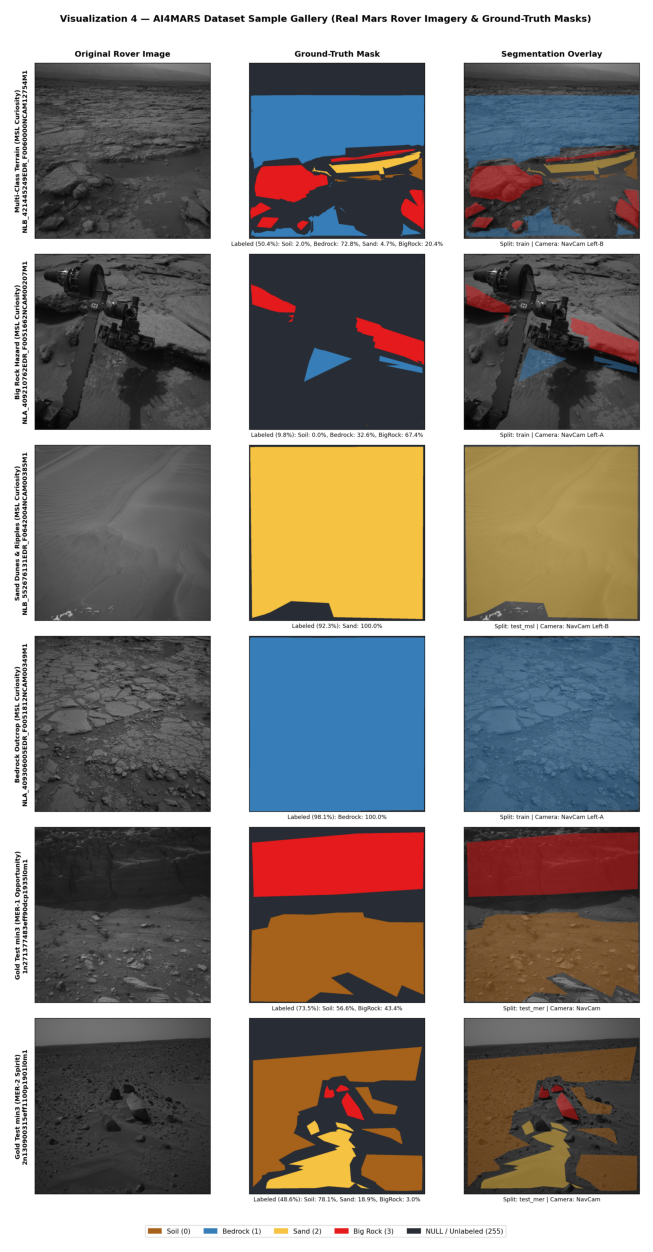

In [5]:
fig, ax = plt.subplots(figsize=(14, 16))
ax.imshow(Image.open(INSP_ROOT / "dataset_samples.png"))
ax.axis("off")
plt.show()

ext_meta_path = EXT_ROOT / "external_samples_metadata.json"
if ext_meta_path.exists():
    ext_meta = json.loads(ext_meta_path.read_text(encoding="utf-8"))
    ext_df = pd.DataFrame(ext_meta.get("samples", []))
    display(ext_df[["mission", "sol", "instrument", "filename"]] if not ext_df.empty else ext_df)

### Analysis: Multi-Rover Coverage & External Domain Gap
The sample gallery demonstrates real ground-truth masks across MSL Curiosity (`NLA`/`NLB` NavCams), MER-1 Opportunity, and MER-2 Spirit. Meanwhile, external qualitative raw images acquired from the official NASA Mars Raw Image APIs (Perseverance M2020 and recent Curiosity sols) differ in sensor resolution, color Bayer RGB vs. grayscale NavCam contrast, and camera mounting geometry—confirming that external M2020 imagery should strictly serve as out-of-distribution qualitative tests until verified annotations are incorporated.

---

## Summary & Key Conclusions for Step 2
1. **Verified Foundation:** All acquired image-mask pairs pass decoding, dimension alignment, and official label-key checks (`{0, 1, 2, 3, 255}`) with zero train/test ID leakage.
2. **Preprocessing Requirements:** Training pipelines must ignore pixel value `255`, preserve aspect/resolution or tile carefully without losing global context, and apply contrast normalization (e.g., CLAHE / mission-standardized normalization) to generalize across MSL and MER cameras.
3. **Imbalance Strategy:** Severe `big rock` scarcity requires weighted Cross-Entropy (`1 - composition` or effective-number weighting) paired with Dice/IoU or Focal loss, evaluated separately across `min1`, `min2`, and `min3` expert gold-standard test splits.
4. **Scientific Boundary:** Visual terrain segmentation identifies surface composition (`soil`, `bedrock`, `sand`, `big rock`) and informs risk cues, but certified rover traversability requires stereo geometry, slope, and terramechanical telemetry.